In [2]:
import sys

# Preserve Jupyter's cell-aware output streams during JaxMARL's import.
notebook_stdout, notebook_stderr = sys.stdout, sys.stderr
try:
    import jaxmarl
finally:
    sys.stdout, sys.stderr = notebook_stdout, notebook_stderr


Importing submoduled environments...
Submoduled environments not found. Skipping import.


In [27]:
%matplotlib inline

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxmarl.viz.overcooked_v2_visualizer import OvercookedV2Visualizer

visualizer = OvercookedV2Visualizer()

def show_state(state):
    # The renderer expects a sequence; wrap this state as a one-frame sequence.
    batch = jax.tree.map(lambda x: jnp.expand_dims(x, 0), state)
    image = np.asarray(visualizer.render_sequence(batch))[0]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image)
    ax.set_title(f"Step {int(state.step)} | red: agent_0, blue: agent_1")
    ax.axis("off")
    plt.show()
    plt.close(fig)


In [31]:
from jaxmarl.environments.overcooked_v2.common import OvercookedActionsEnum

action_names = {
    int(action): action.name.upper()
    for action in OvercookedActionsEnum
}

action_ids = {
    action.name.upper(): int(action)
    for action in OvercookedActionsEnum
}

print(action_names)
print(action_ids)


{0: 'RIGHT', 1: 'DOWN', 2: 'LEFT', 3: 'UP', 4: 'STAY', 5: 'INTERACT'}
{'RIGHT': 0, 'DOWN': 1, 'LEFT': 2, 'UP': 3, 'STAY': 4, 'INTERACT': 5}


In [3]:
from pathlib import Path
import json
from flax import serialization

from train import load_baseline
from evaluate import initialize_policy

run = Path("outputs/train/coord_ring-seed42-20261103T015009421729Z")

# Same simulator version as the saved run.
metadata = json.loads((run / "metadata.json").read_text())
assert metadata["upstream_revision"] == Path("UPSTREAM_REVISION").read_text().strip()

# loads the model metadata (config) and the python module encoding the model (in this case, ippo_rnn.py)
module, config = load_baseline(run / "config.json", seed=None)

# Recreate the kitchen and network structure.
env = module.jaxmarl.make(config["ENV_NAME"], **config["ENV_KWARGS"])
network, template = initialize_policy(module, config, env)

# Replace the freshly initialized weights with the saved weights.
params = serialization.from_bytes(
    template, (run / "params.msgpack").read_bytes()
)
print(config)
print(env.agents)

{'ENV_NAME': 'overcooked_v2', 'ENV_KWARGS': {'layout': 'coord_ring', 'agent_view_size': 2, 'random_agent_positions': True, 'negative_rewards': True, 'max_steps': 400, 'observation_type': 'default', 'random_reset': False, 'start_cooking_interaction': False, 'sample_recipe_on_delivery': False, 'indicate_successful_delivery': False}, 'LR': 0.0005, 'ANNEAL_LR': True, 'LR_WARMUP': 0.05, 'NUM_ENVS': 256, 'NUM_STEPS': 256, 'NUM_MINIBATCHES': 64, 'UPDATE_EPOCHS': 4, 'TOTAL_TIMESTEPS': 10000000, 'REW_SHAPING_HORIZON': 5000000, 'CNN_FEATURES': 32, 'FC_DIM_SIZE': 128, 'GRU_HIDDEN_DIM': 128, 'ACTIVATION': 'relu', 'CLIP_EPS': 0.2, 'ENT_COEF': 0.01, 'GAMMA': 0.99, 'GAE_LAMBDA': 0.95, 'SCALE_CLIP_EPS': False, 'VF_COEF': 0.5, 'MAX_GRAD_NORM': 0.25, 'MINIBATCH_SIZE': 2048, 'SEED': 42, 'NUM_SEEDS': 1, 'ENTITY': '', 'PROJECT': 'se390-overcooked-v2', 'WANDB_MODE': 'disabled', 'ALGORITHM': 'ippo_rnn', 'CHECKPOINT_INTERVAL_UPDATES': 10, 'CHECKPOINT_KEEP_LAST': 3}
['agent_0', 'agent_1']


In [25]:
import jax
import jax.numpy as jnp

# Create random keys for the environment
# needed for initial env state, model actions, rng per step
key = jax.random.PRNGKey(1000)
_key, reset_key, action_key, step_key = jax.random.split(key, 4)

# obs: tensor representing "view" from perspective of each agent.
# state: data encoding the current entire state of the simulation.
# obs can be deterministically gotten from state.
obs, state = env.reset(reset_key)

# Initialize empty GRU
# we can inspect to show that the current GRU is shape [128,]
hidden = module.ScannedRNN.initialize_carry(
    env.num_agents, config["GRU_HIDDEN_DIM"]
)

# Network input axes: (time, chefs, height, width, channels).
obs_batch = jnp.stack([obs[a] for a in env.agents])
inputs = (obs_batch[None], jnp.full((1, env.num_agents), state.done))

# new GRU, probability distribution of actions, and expected return
next_hidden, policy, value = network.apply(params, hidden, inputs)

# Sample one action per chef, then advance the kitchen.
chosen = policy.sample(seed=action_key)[0]
actions = {a: chosen[i] for i, a in enumerate(env.agents)}
next_obs, next_state, rewards, dones, info = env.step_env(
    step_key, state, actions
)

print("Observation batch:", inputs[0].shape)
print("Memory:", hidden.shape)
print("Action probabilities:\n", policy.probs[0])
print("Chosen actions:", {a: int(v) for a, v in actions.items()})
print("Step:", int(next_state.step))
print("Team reward:", float(rewards[env.agents[0]]))
 

Observation batch: (1, 2, 5, 5, 30)
Memory: (2, 128)
Action probabilities:
 [[3.3869492e-04 1.6852975e-04 9.9813640e-01 1.3259980e-04 4.9548928e-04
  7.2827277e-04]
 [3.3230743e-05 1.2449584e-03 3.6909137e-04 7.3758001e-06 2.7827220e-05
  9.9831754e-01]]
Chosen actions: {'agent_0': 2, 'agent_1': 5}
Step: 1
Team reward: 0.0


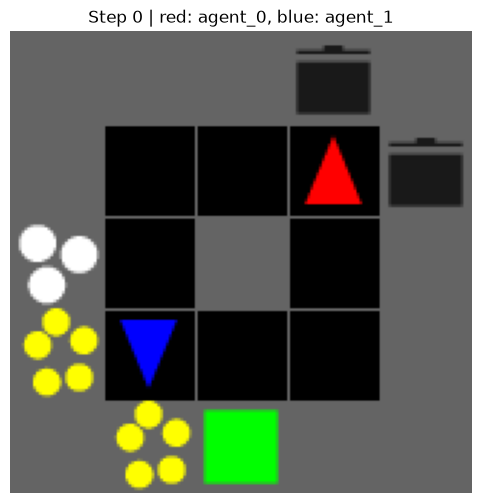

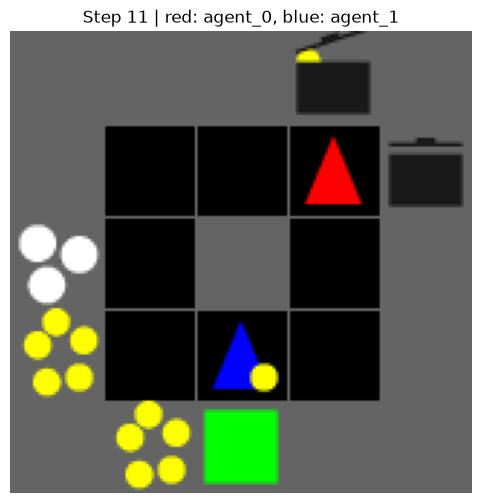

{'RIGHT': Array([[63.908222, 63.926804]], dtype=float32), 'DOWN': Array([[63.24278, 64.39137]], dtype=float32), 'LEFT': Array([[63.387108, 65.40195 ]], dtype=float32), 'UP': Array([[63.526276, 64.66982 ]], dtype=float32), 'STAY': Array([[63.526276, 64.66982 ]], dtype=float32), 'INTERACT': Array([[62.541607, 63.124313]], dtype=float32)}


In [53]:
import jax
import jax.numpy as jnp

# Compile repeated operations for speed. First call takes longer.
policy_step = jax.jit(network.apply)
kitchen_step = jax.jit(env.step_env)

def step_with_user(action: str, state, hidden):
    """
    Does one policy step for one agent while allowing human control of the other agent.
    """
    # New episode: fresh kitchen and zeroed memory.
    key, reset_key = jax.random.split(jax.random.PRNGKey(1000))

    key, action_key, step_key = jax.random.split(key, 3)
    obs = env.get_obs(state)
    obs_batch = jnp.stack([obs[a] for a in env.agents])
    inputs = (obs_batch[None], jnp.full((1, env.num_agents), state.done))

    # Carry the updated memory into the next iteration.
    new_hidden, policy, value = policy_step(params, hidden, inputs)
    chosen = policy.sample(seed=action_key)[0]

    agent0 = env.agents[0]
    agent1 = env.agents[1]
    
    actions = {agent0: chosen[0], agent1: action_ids[action]}

    # Carry the updated observations and kitchen into the next iteration.
    obs, state, rewards, dones, info = kitchen_step(step_key, state, actions)
    return state, rewards, dones, info, new_hidden, value

    
obs, state = env.reset(reset_key)
hidden = module.ScannedRNN.initialize_carry(
    env.num_agents, config["GRU_HIDDEN_DIM"]
)
show_state(state)
v = None
# set up scenario where agent A should heavily benefit from cooperation from agent B.
actions = ["INTERACT", "RIGHT", "RIGHT", "LEFT", "RIGHT", "LEFT", "RIGHT", "LEFT", "UP", "STAY", "STAY"]
for action in actions:
    state, rewards, dones, info, hidden, v = step_with_user(action, state, hidden)
show_state(state)
# counterfactual experiment: in this scenario agent 2 can greatly help agent 1 by placing an onion in the middle.
# We have to do a 2nd step to see the effect of a2's action on a1's value head.
action_to_vmap = {}
for action in action_ids:
    new_state, _rewards, _dones, _info, new_hidden, _v = step_with_user(action, state, hidden)
    _ns, _r, _d, _i, _nh, v = step_with_user("STAY", new_state, new_hidden)
    action_to_vmap[action] = v

import json
print(action_to_vmap)

In [42]:
v

Array([[63.305153, 64.955536]], dtype=float32)

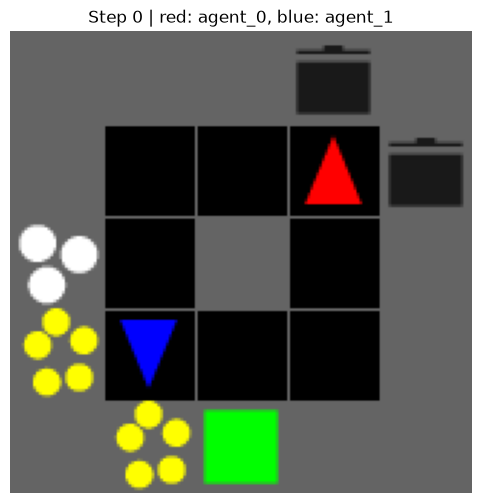

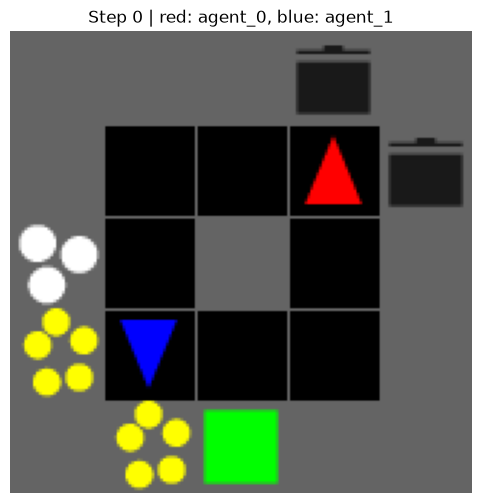

In [30]:
show_state(state)
show_state(state)

In [60]:
print(state.grid.shape)
print(policy)
print(obs["agent_0"].shape)

(5, 5, 3)
(5, 5, 30)
